# Restaurant Sales & Quantity Forecasting (Revised)

This notebook preserves the dataset's original `season` labels, uses one consistent set of lowercase calendar features, adds dish-level historical sales features, relative-price features, festival proximity flags (only from dates present in the dataset), Friday/month-boundary indicators, and a climate/item-type interaction where those columns exist.

Targets are log-transformed for training and training targets are capped at the 99.5th percentile to reduce outlier influence. Predictions are inverse-transformed and constrained to nonnegative values no greater than the training cap. Metrics are evaluated against uncapped actual test targets.

**Data limitation:** The notebook does not invent a festival calendar or weather observations. `days_before_festival`/`days_after_festival` rely on the dataset's `is_festival` flag, and weather effects can only be learned if `climate` or related item-type columns are present. Forecasting is one-day-ahead; lag values for future multi-day forecasts need to be updated recursively.


In [1]:
!pip -q install xgboost

# Data processing
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Upload dataset to Google Colab
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving BA project dataset.zip to BA project dataset.zip
Dataset loaded successfully!
Dataset shape: (155599, 36)


,date,year,month,weekday,is_weekend,season,climate,is_holiday,holiday_religion,is_festival,...,is_chefspecial,dish_popularity,rating,price_per_unit,price_mean,base_low,base_mid,base_high,units_sold,revenue
0,2024-07-22,2024,7,0,0,Rainy,Rainy,0,NaN,0,...,0,7,4.45,53.23,85.0,30,55,80,20,1064.60
1,2023-08-18,2023,8,4,0,Rainy,Rainy,0,NaN,0,...,0,6,4.60,189.49,220.0,8,16,28,5,947.45
2,2024-08-06,2024,8,1,0,Rainy,Humid,0,NaN,0,...,0,6,4.38,359.65,230.0,6,14,26,27,9710.55
3,2023-04-23,2023,4,6,1,Summer,Hot,0,NaN,0,...,0,5,4.06,426.94,390.0,4,9,16,5,2134.70
4,2024-08-03,2024,8,5,1,Rainy,Rainy,0,NaN,0,...,0,6,4.56,55.41,60.0,42,78,115,29,1606.89


In [2]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names and data types
print("\nColumn information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Statistical summary
print("\nStatistical summary:")
display(df.describe(include="all").T)

# Unique values in categorical columns
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))

Number of rows: 155599
Number of columns: 36

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155599 entries, 0 to 155598
Data columns (total 36 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   date                          155599 non-null  object 
 1   year                          155599 non-null  int64  
 2   month                         155599 non-null  int64  
 3   weekday                       155599 non-null  int64  
 4   is_weekend                    155599 non-null  int64  
 5   season                        155599 non-null  object 
 6   climate                       149384 non-null  object 
 7   is_holiday                    155599 non-null  int64  
 8   holiday_religion              12812 non-null   object 
 9   is_festival                   155599 non-null  int64  
 10  working_day                   155599 non-null  int64  
 11  restaurant_id                 155599 n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,155599,730,2023-12-24,221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,155599.0,NaN,NaN,NaN,2023.4999,0.500002,2023.0,2023.0,2023.0,2024.0,2024.0
month,155599.0,NaN,NaN,NaN,6.513834,3.446288,1.0,4.0,7.0,10.0,12.0
weekday,155599.0,NaN,NaN,NaN,2.999023,2.003551,0.0,1.0,3.0,5.0,6.0
is_weekend,155599.0,NaN,NaN,NaN,0.28621,0.45199,0.0,0.0,0.0,1.0,1.0
season,155599,4,Summer,51963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
climate,149384,6,Hot,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_holiday,155599.0,NaN,NaN,NaN,0.08234,0.274883,0.0,0.0,0.0,0.0,1.0
holiday_religion,12812,4,Hindu,8329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_festival,155599.0,NaN,NaN,NaN,0.216325,0.41174,0.0,0.0,0.0,0.0,1.0



date:
date
2023-12-24    221
2024-06-01    219
2023-04-25    219
2023-10-05    218
2024-07-26    218
2024-10-21    218
2024-01-11    218
2024-08-06    217
2024-02-01    217
2024-04-09    217
Name: count, dtype: int64

season:
season
Summer    51963
Rainy     39251
Winter    38377
Autumn    26008
Name: count, dtype: int64

climate:
climate
Hot       31670
Rainy     29497
Cloudy    28648
Humid     25534
Cold      23152
Cool      10883
Name: count, dtype: int64

holiday_religion:
holiday_religion
Hindu        8329
Muslim       1918
Christian    1704
Other         861
Name: count, dtype: int64

restaurant_id:
restaurant_id
R2    51909
R1    51849
R3    51841
Name: count, dtype: int64

restaurant_name:
restaurant_name
Urban Dine     51909
Budget Eats    51849
Elite Feast    51841
Name: count, dtype: int64

restaurant_locality:
restaurant_locality
Mid     51909
Low     51849
High    51841
Name: count, dtype: int64

food_name:
food_name
Sweet Corn Soup (veg)           2244
Pepperoni Pizza (s

In [3]:
print("Dataset shape:", df.shape)

print("\nData types:")
df.info()

print("\nMissing values:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset shape: (155599, 36)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155599 entries, 0 to 155598
Data columns (total 36 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   date                          155599 non-null  object 
 1   year                          155599 non-null  int64  
 2   month                         155599 non-null  int64  
 3   weekday                       155599 non-null  int64  
 4   is_weekend                    155599 non-null  int64  
 5   season                        155599 non-null  object 
 6   climate                       149384 non-null  object 
 7   is_holiday                    155599 non-null  int64  
 8   holiday_religion              12812 non-null   object 
 9   is_festival                   155599 non-null  int64  
 10  working_day                   155599 non-null  int64  
 11  restaurant_id                 155599 non-null  object 
 12  res

,Missing Values
holiday_religion,142787
climate,6215
rating,4677
price_per_unit,3119
revenue,3119
month,0
year,0
date,0
weekday,0
is_holiday,0



Exact duplicate rows: 2299

Date range:
2023-01-01 to 2024-12-30

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,155599,730,2023-12-24,221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,155599.0,NaN,NaN,NaN,2023.4999,0.500002,2023.0,2023.0,2023.0,2024.0,2024.0
month,155599.0,NaN,NaN,NaN,6.513834,3.446288,1.0,4.0,7.0,10.0,12.0
weekday,155599.0,NaN,NaN,NaN,2.999023,2.003551,0.0,1.0,3.0,5.0,6.0
is_weekend,155599.0,NaN,NaN,NaN,0.28621,0.45199,0.0,0.0,0.0,1.0,1.0
season,155599,4,Summer,51963,NaN,NaN,NaN,NaN,NaN,NaN,NaN
climate,149384,6,Hot,31670,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_holiday,155599.0,NaN,NaN,NaN,0.08234,0.274883,0.0,0.0,0.0,0.0,1.0
holiday_religion,12812,4,Hindu,8329,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_festival,155599.0,NaN,NaN,NaN,0.216325,0.41174,0.0,0.0,0.0,0.0,1.0


In [4]:
# Parse dates only. Keep the dataset's original season labels (for example, "Rainy").
# Calendar features are created once in the feature-engineering cell below.
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date parsed. Existing season labels will be preserved.")
if "season" in df.columns:
    print("Original season labels:", sorted(df["season"].dropna().astype(str).unique()))
else:
    print("No original 'season' column found; a season feature will not be fabricated.")

display(df[["date"] + [c for c in ["season", "price_per_unit", "units_sold", "revenue"] if c in df.columns]].head())

Date parsed. Existing season labels will be preserved.
Original season labels: ['Autumn', 'Rainy', 'Summer', 'Winter']


,date,season,price_per_unit,units_sold,revenue
0,2024-07-22,Rainy,53.23,20,1064.60
1,2023-08-18,Rainy,189.49,5,947.45
2,2024-08-06,Rainy,359.65,27,9710.55
3,2023-04-23,Summer,426.94,5,2134.70
4,2024-08-03,Rainy,55.41,29,1606.89


In [5]:
df = df.copy()

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert numerical columns to numeric format
numeric_cols = [
    "year", "month", "weekday", "is_weekend",
    "is_holiday", "is_festival", "working_day",
    "restaurant_demand_multiplier", "is_milkbased",
    "is_chefspecial", "dish_popularity", "rating",
    "price_per_unit", "price_mean", "base_low",
    "base_mid", "base_high", "units_sold", "revenue"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Remove rows without a valid date
df = df.dropna(subset=["date"]).copy()

# Remove rows without valid prediction targets
df = df.dropna(
    subset=["revenue", "units_sold"]
).copy()

# Keep only valid, nonnegative sales and quantity targets
df = df[
    (df["revenue"] >= 0) &
    (df["units_sold"] >= 0)
].copy()

# Sort chronologically
df = df.sort_values("date").reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

display(df.head())

Cleaned dataset shape: (149784, 36)
Remaining duplicates: 0


,date,year,month,weekday,is_weekend,season,climate,is_holiday,holiday_religion,is_festival,...,is_chefspecial,dish_popularity,rating,price_per_unit,price_mean,base_low,base_mid,base_high,units_sold,revenue
0,2023-01-01,2023,1,6,1,Winter,Cold,0,NaN,0,...,0,9,4.94,331.36,300.0,12,25,40,26,8615.36
1,2023-01-01,2023,1,6,1,Winter,Cold,0,NaN,0,...,0,5,NaN,66.19,70.0,25,45,70,19,1257.61
2,2023-01-01,2023,1,6,1,Winter,Cold,0,NaN,0,...,0,6,4.30,268.62,370.0,3,8,14,3,805.86
3,2023-01-01,2023,1,6,1,Winter,Cold,0,NaN,0,...,0,8,4.72,96.61,80.0,60,100,150,148,14298.28
4,2023-01-01,2023,1,6,1,Winter,Cold,0,NaN,0,...,1,6,4.17,62.86,100.0,30,55,80,27,1697.22


In [8]:
# Feature engineering: use one lowercase version of each calendar feature.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"]).copy()
df = df.sort_values("date").reset_index(drop=True)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["weekday"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["weekday" ] >= 5).astype(int)
df["is_friday"] = (df["weekday"] == 4).astype(int)
df["is_month_start"] = df["date"].dt.is_month_start.astype(int)
df["is_month_end"] = df["date"].dt.is_month_end.astype(int)

# Preserve the dataset's original season column. Do not replace labels such as Rainy.
if "season" not in df.columns:
    df["season"] = "Unknown"
df["season"] = df["season"].fillna("Unknown").astype(str)

# Existing festival indicator: measure nearby days only where festival dates are known.
if "is_festival" in df.columns:
    festival_dates = pd.to_datetime(
        df.loc[pd.to_numeric(df["is_festival"], errors="coerce").fillna(0).eq(1), "date"]
        .dt.normalize().drop_duplicates()
    ).sort_values()
else:
    festival_dates = pd.DatetimeIndex([])

if len(festival_dates):
    current_dates = df["date"].dt.normalize()
    # Positive distances are clipped to 7 days; no invented festival calendar is used.
    days_before = []
    days_after = []
    for d in current_dates:
        future_deltas = (festival_dates - d).dt.days
        past_deltas = (d - festival_dates).dt.days
        future_deltas = future_deltas[future_deltas >= 0]
        past_deltas = past_deltas[past_deltas >= 0]
        days_before.append(int(min(future_deltas.min(), 7)) if len(future_deltas) else 7)
        days_after.append(int(min(past_deltas.min(), 7)) if len(past_deltas) else 7)
    df["days_before_festival"] = days_before
    df["days_after_festival"] = days_after
else:
    df["days_before_festival"] = 7
    df["days_after_festival"] = 7

# Price compared with a dish's historical usual price.
# Use only earlier dates for the usual price; fallback to price_mean/current price if needed.
item_keys = [c for c in ["restaurant_id", "food_name"] if c in df.columns]
if not item_keys:
    item_keys = ["category"] if "category" in df.columns else []

if "price_per_unit" in df.columns:
    df["price_per_unit"] = pd.to_numeric(df["price_per_unit"], errors="coerce")
    if item_keys:
        daily_price = (
            df.groupby(["date"] + item_keys, dropna=False)["price_per_unit"]
              .median().rename("daily_item_price").reset_index()
              .sort_values("date")
        )
        daily_price["usual_price"] = (
            daily_price.groupby(item_keys, dropna=False)["daily_item_price"]
            .transform(lambda s: s.shift(1).expanding(min_periods=1).median())
        )
        df = df.merge(
            daily_price[["date"] + item_keys + ["usual_price"]],
            on=["date"] + item_keys, how="left"
        )
    else:
        df["usual_price"] = np.nan

    if "price_mean" in df.columns:
        df["usual_price"] = df["usual_price"].fillna(
            pd.to_numeric(df["price_mean"], errors="coerce")
        )
    df["usual_price"] = df["usual_price"].fillna(df["price_per_unit"])
    df["price_vs_usual"] = (
        df["price_per_unit"] / df["usual_price"].replace(0, np.nan)
    ).replace([np.inf, -np.inf], np.nan).fillna(1.0)

# Historical sales by dish and restaurant, calculated from prior daily totals.
# These are prior-day / prior-week values, not same-day totals.
if "food_name" in df.columns and "units_sold" in df.columns:
    group_keys = [c for c in ["restaurant_id", "food_name"] if c in df.columns]
    item_daily = (
        df.groupby(["date"] + group_keys, dropna=False)
          .agg(dish_units=("units_sold", "sum"),
               dish_revenue=("revenue", "sum"))
          .reset_index()
          .sort_values("date")
    )
    grouped = item_daily.groupby(group_keys, dropna=False, sort=False)
    for target in ["dish_units", "dish_revenue"]:
        item_daily[f"{target}_lag_1"] = grouped[target].shift(1)
        item_daily[f"{target}_lag_7"] = grouped[target].shift(7)
        item_daily[f"{target}_rolling_7"] = grouped[target].transform(
            lambda s: s.shift(1).rolling(7, min_periods=1).mean()
        )

    lag_cols = [
        "dish_units_lag_1", "dish_units_lag_7", "dish_units_rolling_7",
        "dish_revenue_lag_1", "dish_revenue_lag_7", "dish_revenue_rolling_7"
    ]
    df = df.merge(
        item_daily[["date"] + group_keys + lag_cols],
        on=["date"] + group_keys, how="left"
    )

# Use available climate/item-type fields together as an interaction feature.
interaction_parts = [c for c in ["climate", "hot_cold", "foodtype", "category"] if c in df.columns]
if len(interaction_parts) >= 2:
    df["climate_item_type"] = (
        df[interaction_parts].fillna("Unknown").astype(str).agg(" | ".join, axis=1)
    )

print("Feature engineering completed.")
print("Original season values preserved:", sorted(df["season"].dropna().unique()))
display(df[[c for c in [
    "date", "year", "month", "weekday", "is_friday",
    "is_month_start", "is_month_end", "season",
    "price_per_unit", "usual_price", "price_vs_usual",
    "dish_units_lag_1", "dish_units_lag_7", "dish_units_rolling_7",
    "units_sold", "revenue"
] if c in df.columns]].head())

Feature engineering completed.
Original season values preserved: ['Autumn', 'Rainy', 'Summer', 'Winter']


,date,year,month,weekday,is_friday,is_month_start,is_month_end,season,price_per_unit,usual_price,price_vs_usual,dish_units_lag_1,dish_units_lag_7,dish_units_rolling_7,units_sold,revenue
0,2023-01-01,2023,1,6,0,1,0,Winter,331.36,300.0,1.104533,NaN,NaN,NaN,26,8615.36
1,2023-01-01,2023,1,6,0,1,0,Winter,84.22,55.0,1.531273,NaN,NaN,NaN,244,20549.68
2,2023-01-01,2023,1,6,0,1,0,Winter,180.77,170.0,1.063353,NaN,NaN,NaN,35,6326.95
3,2023-01-01,2023,1,6,0,1,0,Winter,251.97,290.0,0.868862,NaN,NaN,NaN,3,755.91
4,2023-01-01,2023,1,6,0,1,0,Winter,261.09,220.0,1.186773,NaN,NaN,NaN,198,51695.82


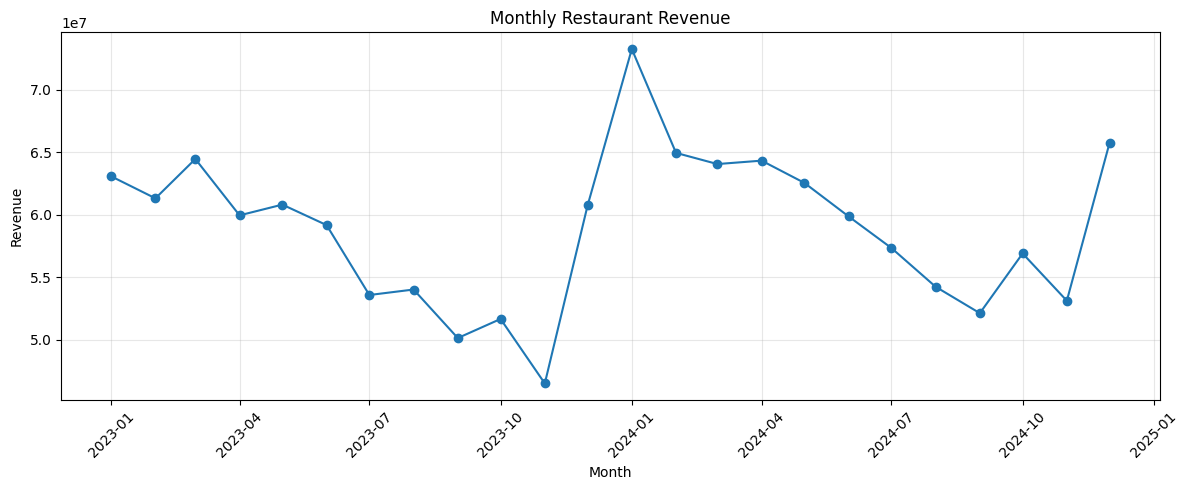

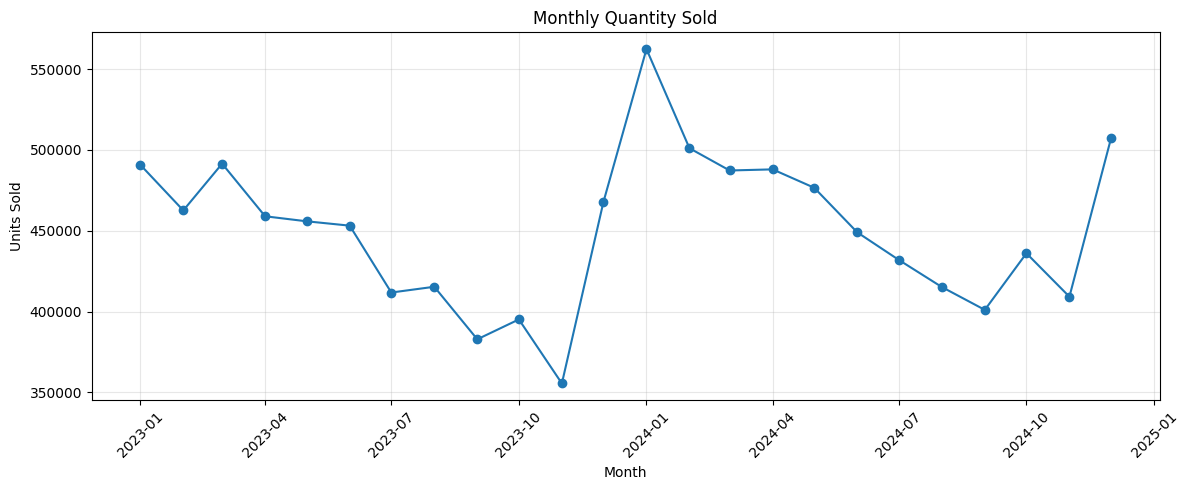

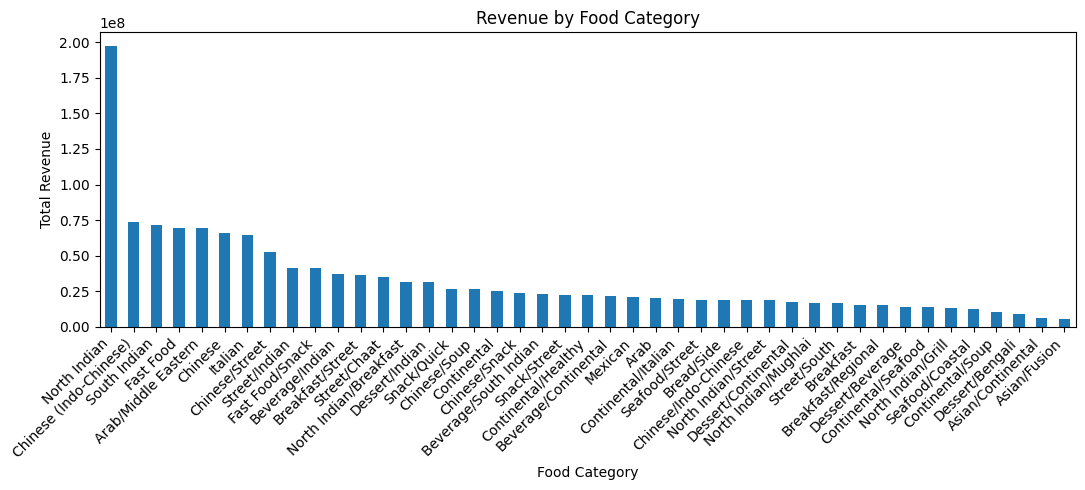

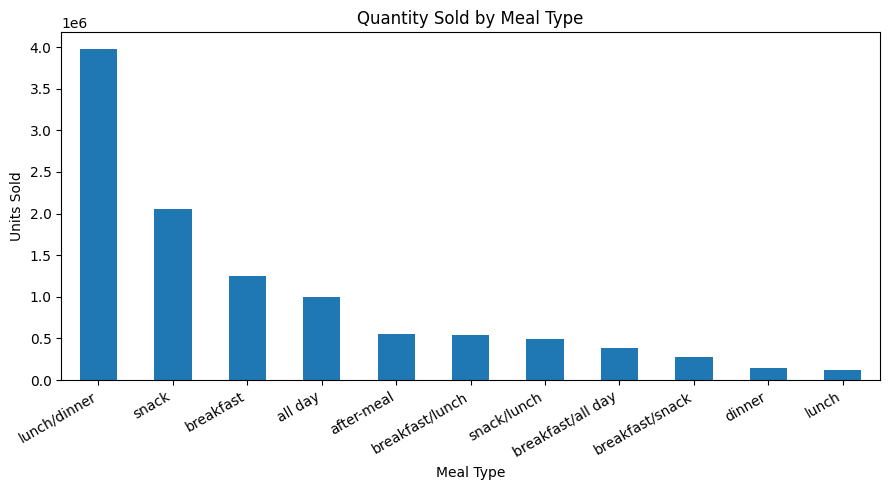

In [9]:
# 1. Monthly revenue
monthly_revenue = (
    df.set_index("date")["revenue"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o"
)
plt.title("Monthly Restaurant Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Monthly quantity sold
monthly_quantity = (
    df.set_index("date")["units_sold"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_quantity.index,
    monthly_quantity.values,
    marker="o"
)
plt.title("Monthly Quantity Sold")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Revenue by food category
category_revenue = (
    df.groupby("category")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 5))
category_revenue.plot(kind="bar")
plt.title("Revenue by Food Category")
plt.xlabel("Food Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 4. Quantity by meal type
meal_quantity = (
    df.groupby("meal_type")["units_sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
meal_quantity.plot(kind="bar")
plt.title("Quantity Sold by Meal Type")
plt.xlabel("Meal Type")
plt.ylabel("Units Sold")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [10]:
# Build a single, deduplicated feature list from columns that actually exist.
# Keep restaurant_id as the restaurant identifier; restaurant_name/locality are excluded
# to avoid redundant encodings of restaurant identity.
numeric_candidates = [
    "year", "month", "day", "weekday", "is_weekend", "is_friday",
    "is_month_start", "is_month_end", "is_holiday", "is_festival",
    "working_day", "days_before_festival", "days_after_festival",
    "restaurant_demand_multiplier", "is_milkbased", "is_chefspecial",
    "dish_popularity", "rating", "price_per_unit", "price_mean",
    "base_low", "base_mid", "base_high", "price_vs_usual",
    "dish_units_lag_1", "dish_units_lag_7", "dish_units_rolling_7",
    "dish_revenue_lag_1", "dish_revenue_lag_7", "dish_revenue_rolling_7"
]

categorical_candidates = [
    "season", "climate", "holiday_religion", "restaurant_id",
    "food_name", "category", "veg_nonveg", "ingredient",
    "foodtype", "meal_type", "hot_cold", "solid_liquid",
    "spice_level", "size", "climate_item_type"
]

numeric_features = list(dict.fromkeys(
    c for c in numeric_candidates if c in df.columns
))
categorical_features = list(dict.fromkeys(
    c for c in categorical_candidates if c in df.columns
))
feature_columns = list(dict.fromkeys(numeric_features + categorical_features))

# Remove identifiers or targets from predictors if they appear unexpectedly.
feature_columns = [
    c for c in feature_columns
    if c not in {"revenue", "units_sold", "restaurant_name", "restaurant_locality"}
]
numeric_features = [c for c in numeric_features if c in feature_columns]
categorical_features = [c for c in categorical_features if c in feature_columns]

X = df[feature_columns].copy()
y_revenue = df["revenue"].astype(float)
y_quantity = df["units_sold"].astype(float)

# Chronological split, ordered by date. All rows from a date stay on one side
# to avoid same-day leakage across train and test.
unique_dates = np.sort(df["date"].dt.normalize().unique())
split_date = unique_dates[int(len(unique_dates) * 0.80)]
train_mask = df["date"].dt.normalize() < split_date
test_mask = ~train_mask

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_revenue_train, y_revenue_test = y_revenue.loc[train_mask], y_revenue.loc[test_mask]
y_quantity_train, y_quantity_test = y_quantity.loc[train_mask], y_quantity.loc[test_mask]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Training records:", len(X_train), "| Testing records:", len(X_test))
print("Training ends:", df.loc[train_mask, "date"].max())
print("Testing starts:", df.loc[test_mask, "date"].min())

Numeric features: ['year', 'month', 'day', 'weekday', 'is_weekend', 'is_friday', 'is_month_start', 'is_month_end', 'is_holiday', 'is_festival', 'working_day', 'days_before_festival', 'days_after_festival', 'restaurant_demand_multiplier', 'is_milkbased', 'is_chefspecial', 'dish_popularity', 'rating', 'price_per_unit', 'price_mean', 'base_low', 'base_mid', 'base_high', 'price_vs_usual', 'dish_units_lag_1', 'dish_units_lag_7', 'dish_units_rolling_7', 'dish_revenue_lag_1', 'dish_revenue_lag_7', 'dish_revenue_rolling_7']
Categorical features: ['season', 'climate', 'holiday_religion', 'restaurant_id', 'food_name', 'category', 'veg_nonveg', 'ingredient', 'foodtype', 'meal_type', 'hot_cold', 'solid_liquid', 'spice_level', 'size', 'climate_item_type']
Training records: 119825 | Testing records: 29959
Training ends: 2024-08-06 00:00:00
Testing starts: 2024-08-07 00:00:00


In [11]:
from xgboost import XGBRegressor

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

def create_model():
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

print("Preprocessing pipeline and XGBoost model created.")

Preprocessing pipeline and XGBoost model created.


In [12]:
# Log-transform targets to reduce the influence of extreme right-tail values.
# Cap only the training targets at their 99.5th percentile; evaluation remains on original values.
revenue_cap = float(y_revenue_train.quantile(0.995))
quantity_cap = float(y_quantity_train.quantile(0.995))

y_revenue_train_capped = y_revenue_train.clip(lower=0, upper=revenue_cap)
y_quantity_train_capped = y_quantity_train.clip(lower=0, upper=quantity_cap)

revenue_model = create_model()
revenue_model.fit(X_train, np.log1p(y_revenue_train_capped))

quantity_model = create_model()
quantity_model.fit(X_train, np.log1p(y_quantity_train_capped))

print("Revenue XGBoost trained with log1p target.")
print(f"Revenue training cap (99.5th percentile): {revenue_cap:.2f}")
print("Quantity XGBoost trained with log1p target.")
print(f"Quantity training cap (99.5th percentile): {quantity_cap:.2f}")

Revenue XGBoost trained with log1p target.
Revenue training cap (99.5th percentile): 62267.40
Quantity XGBoost trained with log1p target.
Quantity training cap (99.5th percentile): 579.00


In [13]:
def evaluate_predictions(y_test, predictions, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    }

# Convert predictions back to original units and enforce nonnegative values.
revenue_predictions = np.expm1(revenue_model.predict(X_test))
revenue_predictions = np.clip(revenue_predictions, 0, revenue_cap)

quantity_predictions = np.expm1(quantity_model.predict(X_test))
quantity_predictions = np.rint(np.clip(quantity_predictions, 0, quantity_cap)).astype(int)

revenue_results = evaluate_predictions(
    y_revenue_test, revenue_predictions, "XGBoost Revenue (log target)"
)
quantity_results = evaluate_predictions(
    y_quantity_test, quantity_predictions, "XGBoost Quantity (log target)"
)

results = pd.DataFrame([revenue_results, quantity_results])
print("MODEL EVALUATION (metrics calculated on original target scale)")
display(results.round(4))

MODEL EVALUATION (metrics calculated on original target scale)


,Model,MAE,RMSE,R2 Score
0,XGBoost Revenue (log target),3224.0518,10520.2731,0.3583
1,XGBoost Quantity (log target),24.1825,91.7955,0.3789


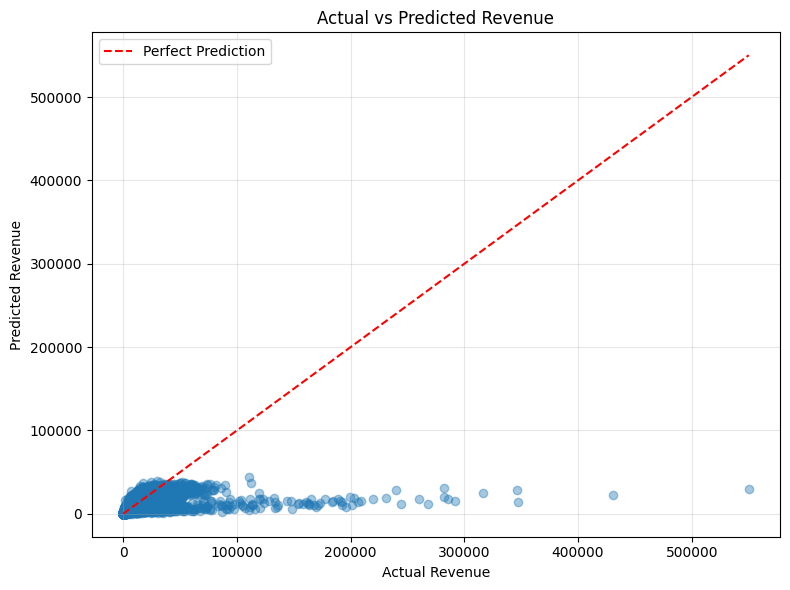

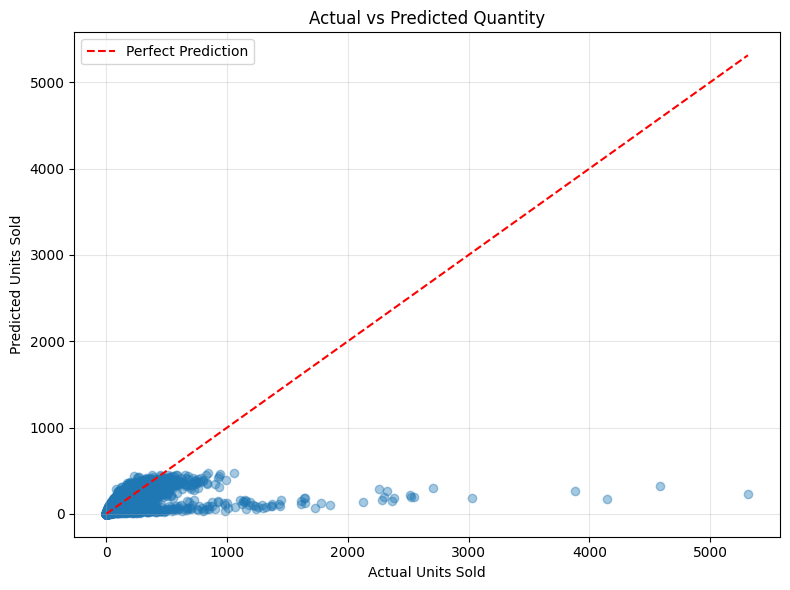

In [14]:
# Revenue: actual vs predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    y_revenue_test,
    revenue_predictions,
    alpha=0.4
)

lower = min(
    y_revenue_test.min(),
    revenue_predictions.min()
)

upper = max(
    y_revenue_test.max(),
    revenue_predictions.max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Quantity: actual vs predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    y_quantity_test,
    quantity_predictions,
    alpha=0.4
)

lower = min(
    y_quantity_test.min(),
    quantity_predictions.min()
)

upper = max(
    y_quantity_test.max(),
    quantity_predictions.max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Units Sold")
plt.ylabel("Predicted Units Sold")
plt.title("Actual vs Predicted Quantity")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
from google.colab import files

# Prediction comparison
comparison = pd.DataFrame({
    "Actual_Revenue": y_revenue_test.to_numpy(),
    "Predicted_Revenue": revenue_predictions,
    "Actual_Quantity": y_quantity_test.to_numpy(),
    "Predicted_Quantity": quantity_predictions
})

comparison["Predicted_Revenue"] = (
    comparison["Predicted_Revenue"].round(2)
)

comparison["Predicted_Quantity"] = (
    comparison["Predicted_Quantity"].round(2)
)

# Save outputs
df.to_csv("cleaned_food_sales.csv", index=False)

comparison.to_csv(
    "actual_vs_predicted.csv",
    index=False
)

results.to_csv(
    "model_evaluation_results.csv",
    index=False
)

print("All output files saved successfully.")

files.download("cleaned_food_sales.csv")
files.download("actual_vs_predicted.csv")
files.download("model_evaluation_results.csv")

All output files saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
comparison = pd.DataFrame({
    "Actual_Revenue": y_revenue_test.to_numpy(),
    "Predicted_Revenue": revenue_predictions,
    "Actual_Quantity": y_quantity_test.to_numpy(),
    "Predicted_Quantity": quantity_predictions
})

comparison["Predicted_Revenue"] = (
    comparison["Predicted_Revenue"].round(2)
)

comparison["Predicted_Quantity"] = (
    comparison["Predicted_Quantity"].round(2)
)

display(comparison.head(20))

# Save comparison to CSV
comparison.to_csv(
    "actual_vs_predicted.csv",
    index=False
)

print("Prediction comparison saved.")

,Actual_Revenue,Predicted_Revenue,Actual_Quantity,Predicted_Quantity
0,6315.40,431.100006,20.0,2
1,4056.12,2937.739990,19.0,15
2,1760.05,2861.050049,5.0,9
3,3659.40,4190.100098,18.0,24
4,25517.76,11701.549805,96.0,50
5,6362.16,9724.490234,56.0,86
6,14934.40,13498.160156,104.0,80
7,3448.38,5445.160156,26.0,41
8,2542.64,3132.850098,37.0,49
9,3319.17,2974.370117,93.0,83


Prediction comparison saved.


In [18]:
# Forecast the next day for the latest known dish/restaurant combinations.
forecast_date = df["date"].max().normalize() + pd.Timedelta(days=1)

item_keys = [c for c in ["restaurant_id", "food_name"] if c in df.columns]
if not item_keys:
    item_keys = [c for c in ["food_name", "category"] if c in df.columns]

future_data = (
    df.sort_values("date")
      .drop_duplicates(subset=item_keys if item_keys else ["date"], keep="last")
      .copy()
)
future_data["date"] = forecast_date

# Recreate the same calendar features used in training.
future_data["year"] = forecast_date.year
future_data["month"] = forecast_date.month
future_data["day"] = forecast_date.day
future_data["weekday"] = forecast_date.dayofweek
future_data["is_weekend"] = int(forecast_date.dayofweek >= 5)
future_data["is_friday"] = int(forecast_date.dayofweek == 4)
future_data["is_month_start"] = int(forecast_date.is_month_start)
future_data["is_month_end"] = int(forecast_date.is_month_end)

# Map future month to the most common original season label observed in that month.
if "season" in df.columns:
    season_by_month = df.groupby(df["date"].dt.month)["season"].agg(
        lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"
    )
    future_data["season"] = season_by_month.get(
        forecast_date.month, df["season"].mode().iloc[0]
    )

# Forecast horizon features use the nearest known festival dates only.
known_festivals = pd.to_datetime(
    df.loc[pd.to_numeric(df.get("is_festival", 0), errors="coerce").fillna(0).eq(1), "date"]
    .dt.normalize().drop_duplicates()
) if "is_festival" in df.columns else pd.DatetimeIndex([])

if len(known_festivals):
    deltas = (known_festivals - forecast_date).dt.days
    before = deltas[deltas >= 0]
    after = -deltas[deltas < 0]
    future_data["days_before_festival"] = int(min(before.min(), 7)) if len(before) else 7
    future_data["days_after_festival"] = int(min(after.min(), 7)) if len(after) else 7
else:
    future_data["days_before_festival"] = 7
    future_data["days_after_festival"] = 7

# Do not invent weather. Reuse the most recent climate/item-type combination.
if "climate_item_type" in feature_columns and "climate_item_type" not in future_data.columns:
    parts = [c for c in ["climate", "hot_cold", "foodtype", "category"] if c in future_data.columns]
    future_data["climate_item_type"] = future_data[parts].fillna("Unknown").astype(str).agg(" | ".join, axis=1)

# Price ratio defaults to 1 if no future price is known.
if "price_vs_usual" in feature_columns:
    future_data["price_vs_usual" ] = future_data.get("price_vs_usual", 1.0)
    future_data["price_vs_usual"] = future_data["price_vs_usual"].fillna(1.0)

# Historical lag features remain the latest known values for this one-day-ahead forecast.
for col in feature_columns:
    if col not in future_data.columns:
        future_data[col] = np.nan

future_X = future_data[feature_columns]
future_data["Predicted_Sales"] = np.clip(
    np.expm1(revenue_model.predict(future_X)), 0, revenue_cap
).round(2)
future_data["Predicted_Quantity"] = np.rint(
    np.clip(np.expm1(quantity_model.predict(future_X)), 0, quantity_cap)
).astype(int)

forecast_output = future_data[
    [c for c in [
        "date", "food_name", "category", "restaurant_name",
        "price_per_unit", "Predicted_Sales", "Predicted_Quantity"
    ] if c in future_data.columns]
].copy()

print("Forecast date:", forecast_date.date())
display(forecast_output.head(20))
forecast_output.to_csv("restaurant_forecast.csv", index=False)
print("Forecast saved to restaurant_forecast.csv")

Forecast date: 2024-12-31


,date,food_name,category,restaurant_name,price_per_unit,Predicted_Sales,Predicted_Quantity
149577,2024-12-31,Egg Curry,North Indian/Breakfast,Budget Eats,123.99,2606.169922,24
149531,2024-12-31,Vada Pav,Street/South,Budget Eats,53.46,3537.129883,81
149378,2024-12-31,Tomato Soup (continental),Continental/Soup,Urban Dine,56.71,3831.689941,73
149386,2024-12-31,Fish Fry (street style),Seafood/Street,Urban Dine,186.87,6460.229980,33
149453,2024-12-31,Fish Fry (street style),Seafood/Street,Budget Eats,195.18,2541.870117,12
149436,2024-12-31,Masala Dosa,South Indian,Budget Eats,106.50,4589.149902,42
149718,2024-12-31,Sushi (salmon),Asian/Fusion,Elite Feast,599.69,4944.689941,8
149711,2024-12-31,Dosa (plain),South Indian,Budget Eats,75.74,1699.150024,23
149712,2024-12-31,Puri Sabzi,Breakfast/Street,Elite Feast,117.53,13507.620117,117
149713,2024-12-31,Filter Coffee,Beverage/South Indian,Elite Feast,93.23,19179.140625,230


Forecast saved to restaurant_forecast.csv


In [19]:
# Overall statistics
total_sales = df["revenue"].sum()
average_sales = df["revenue"].mean()
total_quantity = df["units_sold"].sum()
average_quantity = df["units_sold"].mean()

print("RESTAURANT BUSINESS INSIGHTS")
print("-" * 40)

print(f"Total recorded sales: {total_sales:.2f}")
print(f"Average sales per record: {average_sales:.2f}")
print(f"Total quantity sold: {total_quantity}")
print(f"Average quantity per record: {average_quantity:.2f}")

# Best-performing category
category_summary = (
    df.groupby("category")
    .agg(
        Total_Sales=("revenue", "sum"),
        Total_Quantity=("units_sold", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("\nCategory performance:")
display(category_summary)

print(
    "\nTop sales category:",
    category_summary["Total_Sales"].idxmax()
)

# Sales by day of week
weekday_sales = (
    df.groupby("weekday")["revenue"]
    .mean()
    .sort_values(ascending=False)
)

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

print(
    "\nDay with highest average recorded sales:",
    weekday_names[weekday_sales.index[0]]
)

# Sales by restaurant location
location_sales = (
    df.groupby("restaurant_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nSales by location:")
display(location_sales.to_frame("Total_Sales"))

RESTAURANT BUSINESS INSIGHTS
----------------------------------------
Total recorded sales: 1414239585.92
Average sales per record: 9441.86
Total quantity sold: 10807232
Average quantity per record: 72.15

Category performance:


,Total_Sales,Total_Quantity
category,,
North Indian,1.969972e+08,989340
Chinese (Indo-Chinese),7.372123e+07,326546
South Indian,7.138449e+07,660670
Fast Food,6.953340e+07,406705
Arab/Middle Eastern,6.950693e+07,289520
Chinese,6.612762e+07,354695
Italian,6.465866e+07,217027
Chinese/Street,5.284962e+07,439324
Street/Indian,4.125222e+07,268308



Top sales category: North Indian

Day with highest average recorded sales: Saturday

Sales by location:


,Total_Sales
restaurant_name,
Elite Feast,8.898559e+08
Urban Dine,3.859019e+08
Budget Eats,1.384818e+08


In [20]:
from google.colab import files

# Download model evaluation results
results.to_csv("model_evaluation_results.csv", index=False)

# Download cleaned dataset
df.to_csv("cleaned_restaurant_data.csv", index=False)

# Download the generated output files
files.download("model_evaluation_results.csv")
files.download("cleaned_restaurant_data.csv")
files.download("actual_vs_predicted.csv")
files.download("restaurant_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# The primary forecasting pipeline is defined in cells 5–10.
# This older standalone daily-only experiment was removed to avoid conflicting
# feature definitions, duplicate models, and inconsistent evaluation results.


In [22]:
# Model tuning can be added after the primary feature pipeline has been validated.
# Keep one consistent chronological test set for all model comparisons.


In [23]:
# Baseline comparison should use the same test dates and target as the selected model.
# Do not compare transaction-level targets with daily aggregated predictions.


In [24]:
# Feature importance can be extracted from the fitted XGBoost regressor after
# verifying that the transformed feature names align with the importance array.
